# Zoom lenses: mechanical compensation, cam curves and a real 4× zoom

A zoom lens changes its focal length while the image stays sharp. Moving a
single group of lenses changes the focal length, but it also moves the
image; a second group has to move along a different, non-linear path that
puts the image back. This is **mechanical compensation**: two (or more)
groups ride on cams cut into a rotating barrel, and since the 1950s (the
Zoomar of Back and the Angénieux zooms) it has been the principle of
practically every zoom lens, from TV cameras to phone telephoto modules.

This notebook builds the idea up from thin lenses and then traces a real
lens from a patent:

| section | content |
|---|---|
| 1 | the two group zoom: f = f₁f₂/(f₁ + f₂ − d), the U-shaped path of the front group |
| 2 | the four group zoom: variator, compensator, the cam and its two branches |
| 3 | a real zoom: example 1 of US 7,583,450 (Olympus, 12.3 to 49.1 mm, F/2.9 to F/3.6) |
| 4 | the cam curves of the real lens, and what an imperfect cam does to the focus |
| 5 | image quality across the zoom range: spots, distortion, colour |
| 6 | inner focusing to 250 mm and focus breathing |

The ray tracing is `pyoptics.raytrace`; the thin lens kinematics and the
patent data are in `pyoptics.zoom`. Lens optimization itself is the
subject of notebook 58 (lens optimization), tolerancing of
notebook 70 (Monte Carlo tolerancing).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import zoom, sketch
from pyoptics import raytrace as rt
from pyoptics.materials import LAMBDA_F, LAMBDA_C, LAMBDA_d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. The two group zoom

Two thin lenses of focal lengths $f_1$ and $f_2$ at the separation $d$
have the focal length

$$
f = \frac{f_1 f_2}{f_1 + f_2 - d},
\qquad\text{so}\qquad d(f) = f_1 + f_2 - \frac{f_1 f_2}{f},
$$

and the back focus (rear lens to image) is $b = f\,(1 - d/f_1)$. Changing
$d$ changes $f$; the image moves with $b$. In a zoom both groups move such
that the image plane stays fixed: the rear group moves linearly with $f$
($b$ is linear in $f$), the front group on the curve $-(b + d)$, which has
a minimum. This is the classic wide angle zoom of the 1970s to 1990s
(28–70 mm, 35–70 mm): a negative front group and a positive rear group,
a retrofocus layout at the short end. Its front group moves towards the
image at first and then back out: the U-shaped path that a zoom ring with
a cam has no trouble with but a simple linear slide could not do.

shortest track 80.00 mm at f = 39.93 mm; formula: f = |f1| = 40 mm, L = f1 + 4 f2 = 80 mm


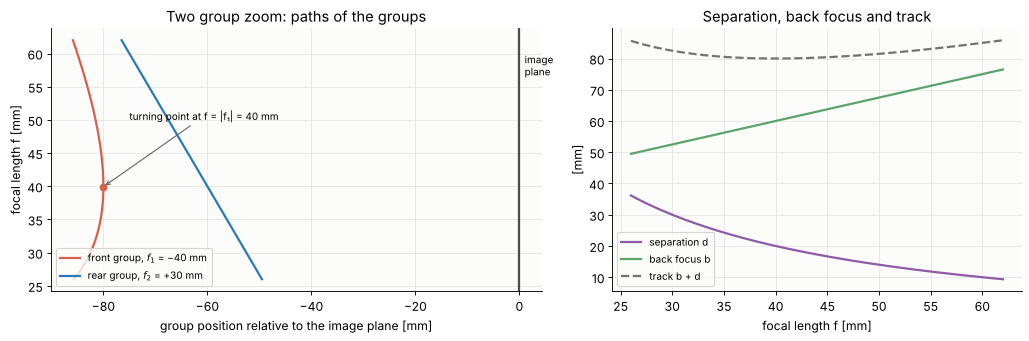

In [2]:
f1, f2 = -40.0, 30.0
efl = np.linspace(26, 62, 200)
d, b = zoom.two_group_zoom(f1, f2, efl)
z_rear, z_front = -b, -(b + d)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
ax0.plot(z_front, efl, color=RED, lw=2, label="front group, $f_1$ = −40 mm")
ax0.plot(z_rear, efl, color=BLUE, lw=2, label="rear group, $f_2$ = +30 mm")
ax0.axvline(0, color="0.3", lw=2)
ax0.text(1, 60, "image\nplane", fontsize=9, va="top")
k_min = np.argmax(z_front)
ax0.plot(z_front[k_min], efl[k_min], "o", color=RED)
ax0.annotate("turning point at f = |f₁| = {:.0f} mm".format(efl[k_min]),
             (z_front[k_min], efl[k_min]), (-75, 50), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="0.4"))
ax0.set_xlabel("group position relative to the image plane [mm]")
ax0.set_ylabel("focal length f [mm]")
ax0.set_title("Two group zoom: paths of the groups")
ax0.legend(loc="lower left", fontsize=9)
ax1.plot(efl, d, color=PURPLE, lw=2, label="separation d")
ax1.plot(efl, b, color=GREEN, lw=2, label="back focus b")
ax1.plot(efl, b + d, color=GREY, lw=2, ls="--", label="track b + d")
ax1.set_xlabel("focal length f [mm]")
ax1.set_ylabel("[mm]")
ax1.set_title("Separation, back focus and track")
ax1.legend(fontsize=9)
fig.tight_layout()

L = b + d
print("shortest track {:.2f} mm at f = {:.2f} mm; formula: f = |f1| = {:.0f} mm, L = f1 + 4 f2 = {:.0f} mm"
      .format(L.min(), efl[np.argmin(L)], abs(f1), f1 + 4*f2))

The track has a simple form. With $d/f_1 = 1 + f_2/f_1 - f_2/f$ the back
focus is $b = f_2 - f f_2/f_1$, and

$$
L = b + d = f_1 + 2 f_2 - f_2\left(\frac{f}{f_1} + \frac{f_1}{f}\right),
$$

which for a negative $f_1$ has its minimum $L = f_1 + 4f_2$ at $f = |f_1|$:
the front group comes closest to the image at the focal length equal to
its own (negative) focal length, and moves out again on either side. With
a negative group in front, both groups must move on *different* laws, one
of them not even monotonic. That is what a cam does.

## 2. The four group zoom: variator and compensator

Most zooms with a large zoom ratio (TV and cine lenses, camcorders,
superzooms) descend from a four group layout:

- **G1**, positive and fixed during zooming (it moves only to focus),
  forms an image of the object.
- **G2**, the negative **variator**, moves and re-images it. Its
  magnification sets the focal length of the whole lens.
- **G3**, the **compensator**, must take the moving image of G2 to a fixed
  point. In the *afocal* version this point is at infinity: G1 to G3 are
  a Galilean telescope of variable magnification.
- **G4**, the fixed **prime** (or relay) lens, forms the final image.

The sketch shows the thin lens version (f = 60, −12, 30, 40 mm) computed by
`zoom.four_group_zoom()`: the variator moves linearly, the compensator
first moves back and then forward again.

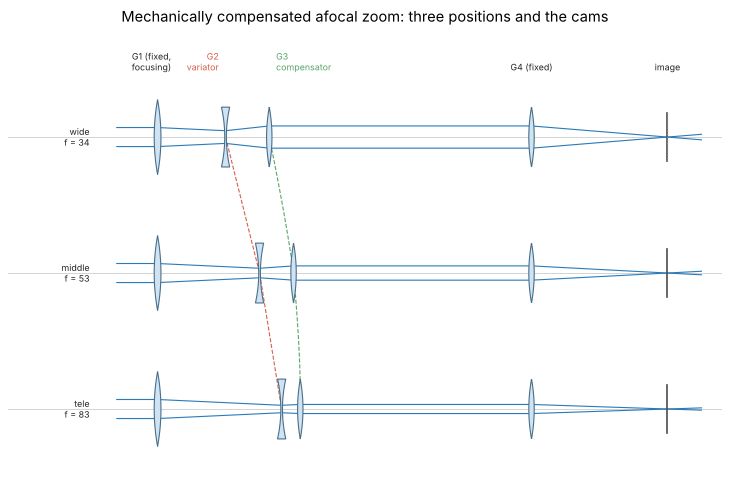

In [3]:
fig, ax = plt.subplots(figsize=(11.5, 6.2))
sketch.zoom_cams(ax, title="Mechanically compensated afocal zoom: three positions and the cams")
fig.tight_layout()

For an afocal compensator the position is $z_3 = a_2 + f_3$ ($a_2$: image
of the variator), one solution for every variator position. If instead
the compensator must form a **real image at a fixed point** (the more
common case in a compact zoom), the condition is a quadratic: for a thin
lens that images a point onto another at the distance $D$,

$$
x^2 - D x + f_3 D = 0,
\qquad x = z_3 - a_2,
$$

so there are **two** compensator positions for every variator position,
one with $|m_3| < 1$ and one with $|m_3| > 1$. They merge where the
compensator works at $m_3 = -1$ ($D = 4f_3$, the shortest conjugate
distance). A cam can follow either branch, or pass from one to the other
exactly at the merging point: this is how designers stretch the zoom
range of a given set of groups (the "zoom through $m = -1$" of Yamaji).

the branches touch at z2 = 36.00 mm, where D = 4 f3 = 80 mm


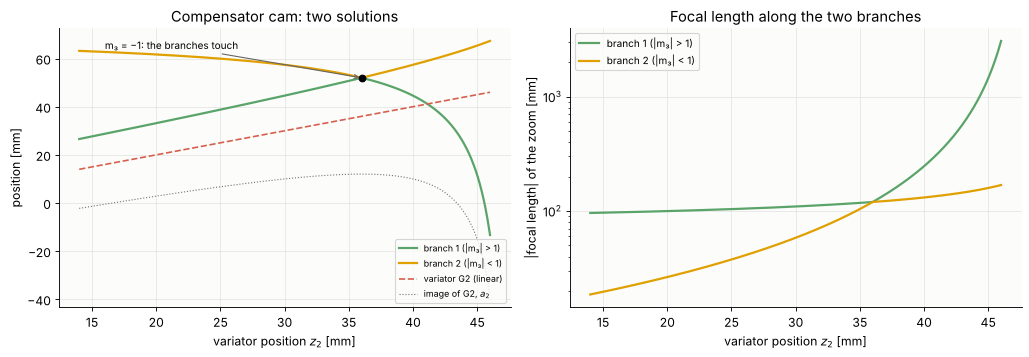

In [4]:
f1, f2, f3, f4 = 60.0, -12.0, 20.0, 40.0
z2 = np.linspace(14, 46, 641)
a2 = zoom.thin_image(f1, z2, f2)          # image of the variator
k = np.argmax(a2)
z_target = a2[k] + 4*f3                   # D = 4 f3 exactly once: the branches touch there
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.6))
for branch, col, name in ((0, GREEN, "branch 1 (|m₃| > 1)"), (1, ORANGE, "branch 2 (|m₃| < 1)")):
    z3, efl4, zi = zoom.four_group_zoom(f1, f2, f3, f4, z2, z4=z_target + 60.0,
                                        z_target=z_target, branch=branch)
    ax0.plot(z2, z3, color=col, lw=2, label=name)
    ax1.plot(z2, np.abs(efl4), color=col, lw=2, label=name)
ax0.plot(z2, z2, color=RED, lw=1.5, ls="--", label="variator G2 (linear)")
ax0.plot(z2, a2, color=GREY, lw=1, ls=":", label="image of G2, $a_2$")
ax0.plot(z2[k], a2[k] + 2*f3, "ko")
ax0.annotate("m₃ = −1: the branches touch", (z2[k], a2[k] + 2*f3), (z2[k] - 20, a2[k] + 2*f3 + 12),
             fontsize=9, arrowprops=dict(arrowstyle="->", color="0.4"))
ax0.set_xlabel("variator position $z_2$ [mm]")
ax0.set_ylabel("position [mm]")
ax0.set_title("Compensator cam: two solutions")
ax0.legend(fontsize=8, loc="lower right")
ax1.set_xlabel("variator position $z_2$ [mm]")
ax1.set_ylabel("|focal length| of the zoom [mm]")
ax1.set_yscale("log")
ax1.set_title("Focal length along the two branches")
ax1.legend(fontsize=9)
fig.tight_layout()
print("the branches touch at z2 = {:.2f} mm, where D = 4 f3 = {:.0f} mm".format(z2[k], 4*f3))

Both branches give a sharp image, but at different focal lengths. Here
the fixed point is chosen such that the conjugate distance of the
compensator just reaches its minimum $4f_3$ at one variator position:
there the two branches touch, and a cam can pass from one to the other,
continuing the zoom in the same direction with the compensator turning
round. Real zoom
lenses have more moving groups than this (the Olympus lens below moves
all of them), which gives the designer freedom to keep the aberrations
corrected over the range and the lens short at the wide end, at the price
of more cams.

## 3. A real zoom: US 7,583,450, example 1

The Olympus patent US 7,583,450 B2 (2009) describes zoom lenses for Four
Thirds cameras. Example 1 has $f$ = 12.31 to 49.14 mm at F/2.88 to
F/3.57, with four groups (+, −, +, +): a front doublet and meniscus (G1);
a negative group G2 of a meniscus, an aspheric meniscus and a cemented
doublet with an S-FPL53 fluorophosphate element; a negative aspheric
lens directly behind it that does the focusing; the aperture stop and a
weak group G3; and the main positive group G4 with seven elements, two
of them of the ED glasses S-FPL53 and S-FPL51. A 4.6 mm cover glass and
filter stack sits in front of the sensor.

`zoom.olympus_zoom_us7583450()` holds the prescription exactly as
printed (radii, thicknesses, $n_d$ and $V_d$ for the 17 elements, six
aspheric surfaces and the table of the six variable spacings at the
wide, middle and tele position). The patent lists $n_d$ and $V_d$; they
are replaced by the nearest glasses of the OHARA catalogue (which match
to the fourth decimal), so the trace has real dispersion curves. The
patent gives no field angle; we take the image height of 10.8 mm, half
the diagonal of the Four Thirds sensor.

The first check of transcribed data is always first order: the focal
lengths and the back focus must come out as printed.

In [5]:
Z = zoom.olympus_zoom_us7583450()
names = ["G1", "G2", "focus lens", "stop", "G3", "G4"]
print("position   f patent   f traced    F/#    image distance (patent: 1.0603 mm behind the plate)")
for k, label in enumerate(["wide", "middle", "tele"]):
    s = Z.system(k)
    p = s.paraxial()
    print("{:7s}   {:7.2f}   {:9.3f}   {:5.2f}   {:9.4f} mm".format(label, Z.focal_lengths[k], p.efl,
                                                                  p.f_number, p.image_distance))
fg = Z.group_focal_lengths()
print("\ngroup focal lengths: " + ", ".join("{} {:.1f} mm".format(n, f) for n, f in zip(names, fg)
                                         if np.isfinite(f)))
glass_list = [s.material for s in Z.base.surfaces if s.material is not None]
print("\nglasses:", ", ".join(sorted({g.name for g in glass_list})))
print("anomalous partial dispersion (|ΔP_gF| > 0.02):",
      ", ".join(sorted({"{} ({:+.3f})".format(g.name, g.dPgF) for g in glass_list
                        if g.dPgF is not None and abs(g.dPgF) > 0.02})))

position   f patent   f traced    F/#    image distance (patent: 1.0603 mm behind the plate)
wide        12.31      12.307    2.88      1.0627 mm
middle      24.42      24.418    3.20      1.0666 mm
tele        49.14      49.150    3.57      1.0748 mm

group focal lengths: G1 110.1 mm, G2 -30.7 mm, focus lens -41.7 mm, G3 200.3 mm, G4 29.0 mm

glasses: L-LAH53, LAH66, LAL14, S-BAL41, S-BSL7, S-FPL51, S-FPL53, S-LAH58, S-LAH97, S-TIM3, TIH14, TIH53
anomalous partial dispersion (|ΔP_gF| > 0.02): S-FPL51 (+0.031), S-FPL53 (+0.050)


The focal lengths agree with the patent to 0.01 mm and the back focus to
about 2 to 14 µm (the catalogue glasses differ from the patent's indices
in the fifth decimal). The group powers show the classic layout: a weak
positive front group (+110 mm), a strong negative variator (−31 mm) and
a strong positive rear group (+29 mm), with a weak G3 (+200 mm). The
negative focusing lens (−42 mm) sits where the beam is nearly
collimated behind G2, so it can focus with little change of the
aberrations.

The layout at the three positions, with the image plane fixed, shows how
every group moves:

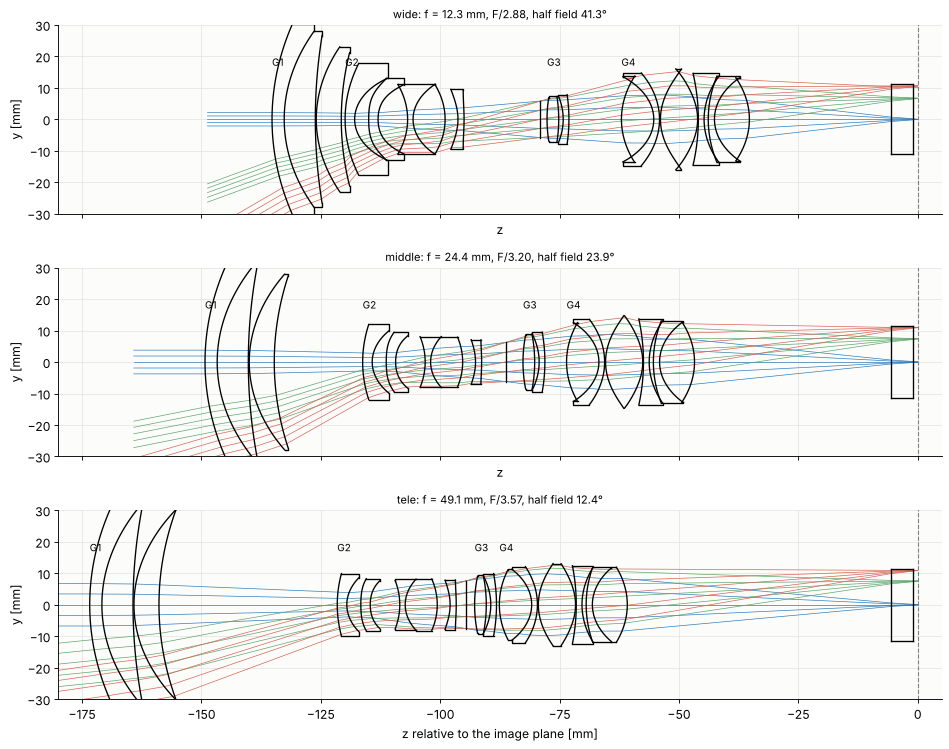

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9.5), sharex=True)
for k, ax in enumerate(axes):
    s = Z.system(k)
    th = np.arctan(10.8/s.paraxial().efl)
    z0 = s.image_z
    s.draw(ax=ax, fields=[0.0, 0.7*th, th], n_rays=5, lw=0.6,
           colors=[BLUE, GREEN, RED])
    # shift the drawing so that the image plane is at 0
    for line in ax.lines:
        line.set_xdata(np.asarray(line.get_xdata()) - z0)
    for zg, n in zip(Z.group_positions(s), names):
        if n in ("G1", "G2", "G3", "G4"):
            ax.text(zg, 17, n, ha="left", fontsize=9)
    ax.set_aspect("auto")
    ax.set_xlim(-180, 5)
    ax.set_ylim(-30, 30)
    ax.set_title("{}: f = {:.1f} mm, F/{:.2f}, half field {:.1f}°".format(
        ["wide", "middle", "tele"][k], s.paraxial().efl, s.paraxial().f_number, np.degrees(th)),
        fontsize=10)
    ax.set_ylabel("y [mm]")
axes[-1].set_xlabel("z relative to the image plane [mm]")
fig.tight_layout()

From wide to tele the front group travels 38 mm forward (the lens gets
longer), the variator G2 stays nearly in place relative to the image, and
the stop, G3 and G4 move forward by 15 to 25 mm, each on its own law. The
air space between G1 and G2 opens from 0.8 to 37 mm: G2 then sits much
further from G1, which raises its magnification, the main zooming
action.

## 4. The cam curves and an imperfect cam

A patent gives the spacings at a few positions only. In between, the cam
must keep the image in focus. We interpolate the tabulated spacings
quadratically over $\log f$ (three points) and check where the paraxial
image lands. Then we let the focusing lens take up the error, the way a
camera with autofocus does, and plot the resulting **cam curves**: the
group positions over the zoom range.

largest image shift with interpolated spacings: 800 µm (depth of focus ±48 µm)
largest focal length error of the interpolation: 0.51 mm


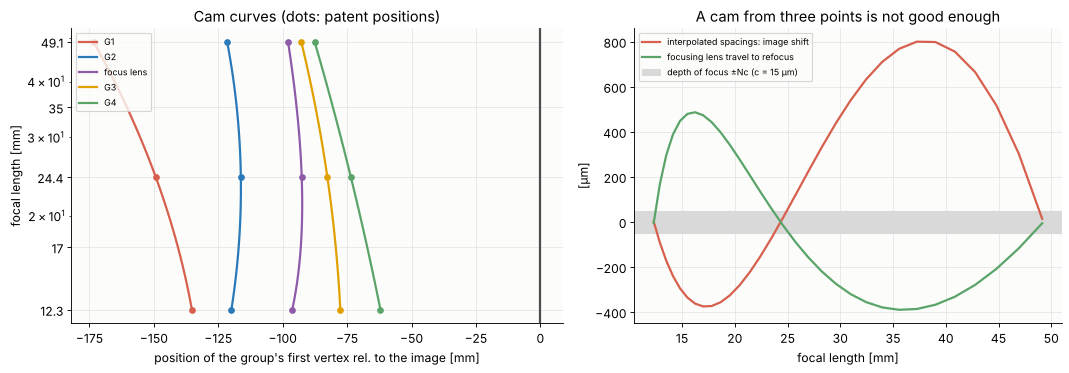

In [7]:
f_grid = np.geomspace(Z.focal_lengths[0], Z.focal_lengths[-1], 31)
focus_gaps = (11, 13)            # the gaps around the focusing lens r13/r14
raw_err, efl_raw, efl_fix, shift, pos = [], [], [], [], []
for f in f_grid:
    s = Z.system(float(f))
    p = s.paraxial()
    raw_err.append(p.image_distance - s.surfaces[-1].thickness)
    efl_raw.append(p.efl)
    s2, dt = Z.refocus(s, focus_gaps)
    shift.append(dt)
    efl_fix.append(s2.paraxial().efl)
    pos.append(Z.group_positions(s2))
raw_err, shift, pos = np.array(raw_err), np.array(shift), np.array(pos)

DOF = 3.2*0.015     # depth of focus ±N c for N ≈ 3.2 and c = 15 µm (Four Thirds)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
cols = [RED, BLUE, PURPLE, GREY, ORANGE, GREEN]
for j, (n, c) in enumerate(zip(names, cols)):
    if n == "stop":
        continue
    ax0.plot(pos[:, j], f_grid, color=c, lw=2, label=n)
    for k in range(3):
        ax0.plot(Z.group_positions(Z.system(k))[j], Z.focal_lengths[k], "o", color=c, ms=5)
ax0.axvline(0, color="0.3", lw=2)
ax0.set_yscale("log")
ax0.set_yticks([12.31, 17, 24.42, 35, 49.14])
ax0.set_yticklabels(["12.3", "17", "24.4", "35", "49.1"])
ax0.set_xlabel("position of the group's first vertex rel. to the image [mm]")
ax0.set_ylabel("focal length [mm]")
ax0.set_title("Cam curves (dots: patent positions)")
ax0.legend(fontsize=8, loc="upper left")
ax1.plot(f_grid, raw_err*1e3, color=RED, lw=2, label="interpolated spacings: image shift")
ax1.plot(f_grid, shift*1e3, color=GREEN, lw=2, label="focusing lens travel to refocus")
ax1.axhspan(-DOF*1e3, DOF*1e3, color="0.85", label="depth of focus ±Nc (c = 15 µm)")
ax1.set_xlabel("focal length [mm]")
ax1.set_ylabel("[µm]")
ax1.set_title("A cam from three points is not good enough")
ax1.legend(fontsize=8)
fig.tight_layout()
print("largest image shift with interpolated spacings: {:.0f} µm (depth of focus ±{:.0f} µm)"
      .format(np.abs(raw_err).max()*1e3, DOF*1e3))
print("largest focal length error of the interpolation: {:.2f} mm".format(
    np.max(np.abs(np.array(efl_raw) - f_grid))))

Interpolating the spacings smoothly through the three tabulated points
puts the image up to 0.8 mm off between them, more than fifteen times the
depth of focus, and the focal length up to 0.5 mm off: the real cams are
not the simplest curves through three points. Here the focusing lens takes the error up (a few tenths of a
millimetre of travel), which is exactly what a modern lens with
autofocus and electronically coupled zoom and focus motors does: the
focus group is driven on a stored table rather than a mechanical cam. In
a purely mechanical (parfocal) zoom, the cam itself has to be cut to
better than the depth of focus divided by the focus sensitivity.

**Focus sensitivity.** How far does the image move when a group moves
by $\delta z$ and everything else stays? For a group of lateral
magnification $m$ followed by groups of total magnification $m'$, the
image moves by $(1 - m^2)\,m'^2\,\delta z$. The table below measures it by
moving each group by 10 µm in the traced lens.

In [8]:
moves = {"G1": (None, 4), "G2": (4, 11), "focus lens": (11, 13), "stop + G3": (13, 18),
         "G4": (18, 28)}
dz = 0.01
print("{:12s} {:>10s} {:>10s} {:>10s}   (image shift per group shift)".format("group", "wide",
                                                                             "middle", "tele"))
sens = {}
for n, (i, j) in moves.items():
    row = []
    for k in range(3):
        s = Z.system(k)
        o = s.copy()
        if i is not None:
            o.surfaces[i].thickness += dz
        o.surfaces[j].thickness -= dz
        # the image plane stays fixed: compare paraxial image positions
        row.append((o.paraxial().image_distance - s.paraxial().image_distance)/dz)
    sens[n] = row
    print("{:12s} {:10.3f} {:10.3f} {:10.3f}".format(n, *row))

group              wide     middle       tele   (image shift per group shift)
G1                0.013      0.049      0.199
G2                0.064      0.127      0.126
focus lens        0.509      1.267      2.705
stop + G3        -0.215     -0.435     -0.813
G4                0.631     -0.007     -1.215


The front group G1 barely matters (its magnification is zero for an
object at infinity, so its sensitivity is just $m'^2 = (f/f_1)^2$, 0.013
at the wide end). The focusing lens has the largest sensitivity, 0.5 at
wide to 2.7 at tele, which is why it was chosen for focusing: a small,
light lens with a large lever. G4 shows the effect of $1 - m^2$: at the
middle position its magnification is close to −1 and the image hardly
moves at all (−0.007), so G4 could not serve as the compensator there.

**A Monte Carlo of cam errors** (in the spirit of
notebook 70 (Monte Carlo tolerancing)): each moving group gets an
independent, normally distributed axial error of σ, and the image shift
is the sum of the sensitivities times the errors. The yield is the
fraction of lenses whose image stays within a third of the depth of
focus (a typical allocation: the rest goes to the flange distance, the
sensor tilt and the lens itself).

wide   : image shift 0.84 × σ_cam (rss of the sensitivities)
middle : image shift 1.35 × σ_cam (rss of the sensitivities)
tele   : image shift 3.08 × σ_cam (rss of the sensitivities)


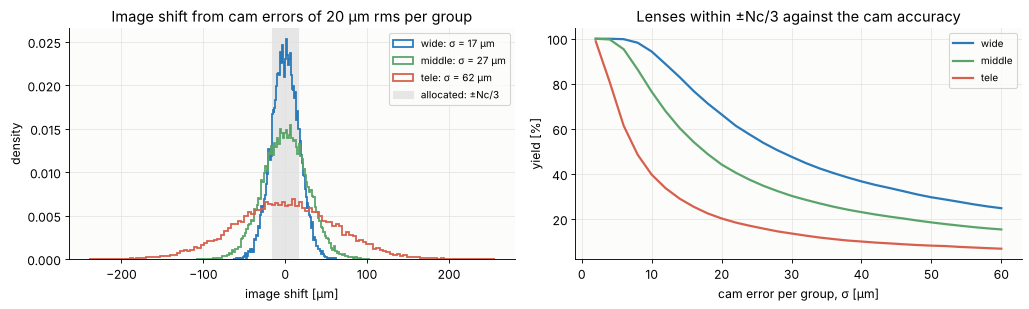

In [9]:
rng = np.random.default_rng(127)
S = np.array([sens[n] for n in moves])        # (groups, positions)
sigmas = np.linspace(2e-3, 0.06, 30)
unit = rng.normal(0, 1, (20000, len(moves)))
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.0))
for k, (col, label) in enumerate(zip([BLUE, GREEN, RED], ["wide", "middle", "tele"])):
    yields = [np.mean(np.abs(sg*unit @ S[:, k]) < DOF/3) for sg in sigmas]
    ax1.plot(sigmas*1e3, np.array(yields)*100, color=col, lw=2, label=label)
    sh = 0.02*unit @ S[:, k]
    ax0.hist(sh*1e3, bins=120, histtype="step", color=col, lw=1.6, density=True,
             label="{}: σ = {:.0f} µm".format(label, sh.std()*1e3))
ax0.axvspan(-DOF/3*1e3, DOF/3*1e3, color="0.9", zorder=0, label="allocated: ±Nc/3")
ax0.set_xlabel("image shift [µm]")
ax0.set_ylabel("density")
ax0.set_title("Image shift from cam errors of 20 µm rms per group")
ax0.legend(fontsize=9)
ax1.set_xlabel("cam error per group, σ [µm]")
ax1.set_ylabel("yield [%]")
ax1.set_title("Lenses within ±Nc/3 against the cam accuracy")
ax1.legend(fontsize=9)
fig.tight_layout()
for k, label in enumerate(["wide", "middle", "tele"]):
    print("{:7s}: image shift {:.2f} × σ_cam (rss of the sensitivities)".format(
        label, np.sqrt(np.sum(S[:, k]**2))))

At the tele end every micrometre of cam error moves the image by three
(the root sum square of the sensitivities, 3.1), at the wide end by less
than one. Keeping 95 % of the lenses within ±Nc/3 = ±16 µm needs cams that
hold each group to about 10 µm at the wide end but 3 µm at the tele end:
the tele end sets the machining tolerance of the cam barrel.

## 5. Image quality across the zoom range

Spot sizes (polychromatic, F, d and C lines at equal weight, each traced at
its own wavelength and referred to the d-line chief ray) and the
distortion of the chief ray against the ideal image height $f\tan\theta$.
The patent gives no clear apertures, so the trace does not vignette
oblique rays; real lenses clip the rim of the oblique beams, which
improves the corners, especially at the wide end.

wide    f =  12.3 mm: rms spot  3.3 µm on axis,  7.0 µm at 0.7 field; distortion -1.50 % at the corner
middle  f =  24.4 mm: rms spot  5.4 µm on axis,  8.5 µm at 0.7 field; distortion +1.83 % at the corner
tele    f =  49.1 mm: rms spot  5.2 µm on axis,  8.0 µm at 0.7 field; distortion +0.81 % at the corner


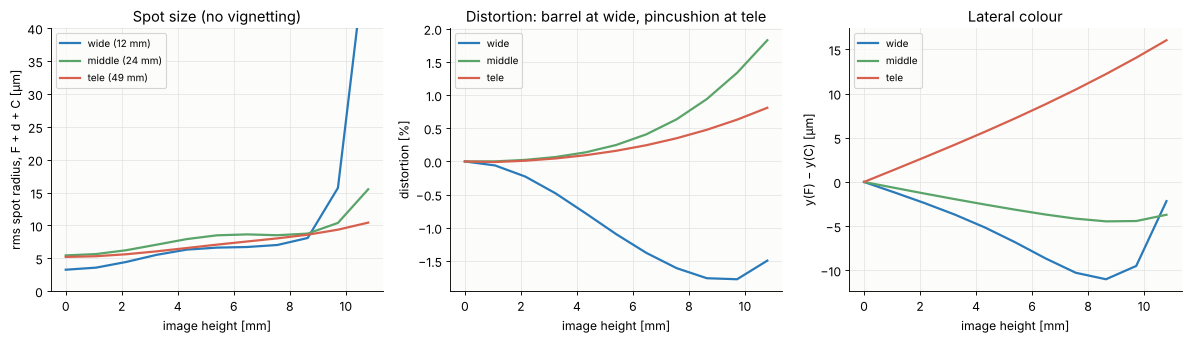

In [10]:
wl = {"F": LAMBDA_F*1e-6, "d": LAMBDA_d*1e-6, "C": LAMBDA_C*1e-6}
fr = np.linspace(0, 1, 11)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
summary = []
for k, (label, col) in enumerate(zip(["wide", "middle", "tele"], [BLUE, GREEN, RED])):
    s = Z.system(k)
    f = s.paraxial().efl
    th_max = np.arctan(10.8/f)
    rms, dist, lat = [], [], []
    for x in fr:
        th = x*th_max
        hits = []
        y_chief = s.trace_pupil(th, 0.0, 0.0).points[-1][0, 1]
        for w in wl.values():
            sw = s.with_wavelength(w)
            sp = sw.spot_diagram(th, N=15)
            yc = sw.trace_pupil(th, 0.0, 0.0).points[-1][0, 1]
            hits.append(np.c_[sp.x, sp.y + yc - y_chief])
        H = np.concatenate(hits)
        H = H - H.mean(axis=0)
        rms.append(np.sqrt(np.mean(np.sum(H**2, axis=1))))
        dist.append(0 if x == 0 else 100*(y_chief/(f*np.tan(th)) - 1))
        yF = s.with_wavelength(wl["F"]).trace_pupil(th, 0.0, 0.0).points[-1][0, 1]
        yC = s.with_wavelength(wl["C"]).trace_pupil(th, 0.0, 0.0).points[-1][0, 1]
        lat.append(yF - yC)
    summary.append((label, f, np.array(rms), np.array(dist), np.array(lat)))
    axes[0].plot(fr*10.8, np.array(rms)*1e3, color=col, lw=2, label="{} ({:.0f} mm)".format(label, f))
    axes[1].plot(fr*10.8, dist, color=col, lw=2, label=label)
    axes[2].plot(fr*10.8, np.array(lat)*1e3, color=col, lw=2, label=label)
axes[0].set_ylabel("rms spot radius, F + d + C [µm]")
axes[0].set_title("Spot size (no vignetting)")
axes[0].set_ylim(0, 40)
axes[1].set_ylabel("distortion [%]")
axes[1].set_title("Distortion: barrel at wide, pincushion at tele")
axes[2].set_ylabel("y(F) − y(C) [µm]")
axes[2].set_title("Lateral colour")
for ax in axes:
    ax.set_xlabel("image height [mm]")
    ax.legend(fontsize=9)
fig.tight_layout()
for label, f, rms, dist, lat in summary:
    print("{:7s} f = {:5.1f} mm: rms spot {:4.1f} µm on axis, {:4.1f} µm at 0.7 field; "
          "distortion {:+.2f} % at the corner".format(label, f, rms[0]*1e3, rms[7]*1e3, dist[-1]))

The spots are 3 to 10 µm over most of the field at all three positions,
comparable to two or three pixels of a 16 MP Four Thirds sensor (3.7 µm
pitch): the lens is corrected over the whole range, not just at one
focal length, which is the actual difficulty of zoom design. Distortion
follows the textbook pattern of a zoom with a negative variator: barrel
(about −1.5 %) at the wide end, where the lens is a retrofocus with the
negative group in front of the stop, pincushion from the middle position
on (+1.8 % at 24 mm, +0.8 % at 49 mm), where the positive groups dominate.
Lateral colour stays within ±16 µm, a few pixels at the corner at the
tele end. Only the full field at the wide end blows
up (the rim of the 41° beam, which a real barrel vignettes).

**Axial colour.** The ED glasses are there for the secondary spectrum. The
focus against wavelength (paraxial) at the three positions:

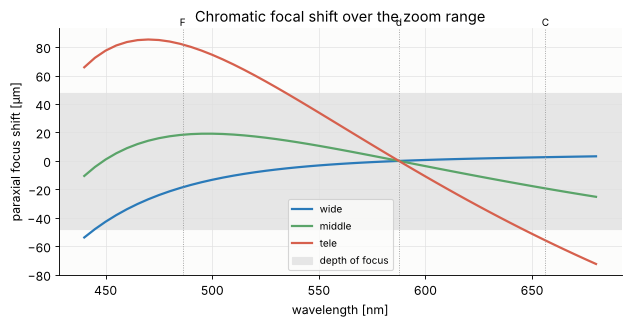

In [11]:
lam = np.linspace(440, 680, 49)
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, (label, col) in enumerate(zip(["wide", "middle", "tele"], [BLUE, GREEN, RED])):
    s = Z.system(k)
    z_d = s.paraxial().image_distance
    shift = [s.with_wavelength(l*1e-6).paraxial().image_distance - z_d for l in lam]
    ax.plot(lam, np.array(shift)*1e3, color=col, lw=2, label=label)
ax.axhspan(-DOF*1e3, DOF*1e3, color="0.9", zorder=0, label="depth of focus")
for l, n in ((LAMBDA_F, "F"), (LAMBDA_d, "d"), (LAMBDA_C, "C")):
    ax.axvline(l, color="0.6", lw=0.8, ls=":")
    ax.text(l, ax.get_ylim()[1], n, ha="center", va="bottom", fontsize=9)
ax.set_xlabel("wavelength [nm]")
ax.set_ylabel("paraxial focus shift [µm]")
ax.set_title("Chromatic focal shift over the zoom range")
ax.legend(fontsize=9)
fig.tight_layout()

At the wide end the focus stays within the depth of focus over the whole
visible range. Towards the tele end the curve tilts: the blue focuses
behind the red by about 0.1 mm, more than the depth of focus, the price
of a compact long end (the patent's own aberration plots show the same
trend). A colour corrected tele end would need yet more anomalous glass
or a larger lens.

## 6. Focusing to 250 mm and focus breathing

The patent also lists the spacings for an object at 250 mm (measured
from the object to the image plane). Focusing moves the small negative
lens r13/r14 towards the object by about 2 mm, and the variator G2 by
0.2 mm; G1, the heaviest group, stays put (inner focusing, fast and
silent for autofocus). With the patent's close-up spacings the object
that is in focus should lie 250 mm in front of the image plane:

In [12]:
from scipy.optimize import brentq
N = zoom.olympus_zoom_us7583450(near=True)
print("position   object to image plane   f at infinity   f at the close focus")
for k, label in enumerate(["wide", "middle", "tele"]):
    s = N.system(k)
    img = s.surfaces[-1].thickness

    def err(od):
        o = s.copy()
        o.object_distance = od
        return o.paraxial().image_distance - img

    od = brentq(err, 30, 1e4)
    s.object_distance = od
    track = s.image_z - s.vertex_z[0]
    print("{:7s}   {:10.1f} mm   {:12.2f} mm   {:12.2f} mm".format(
        label, od + track, Z.system(k).paraxial().efl, N.system(k).paraxial().efl))

position   object to image plane   f at infinity   f at the close focus
wide           249.6 mm          12.31 mm          11.90 mm
middle         249.6 mm          24.42 mm          22.11 mm
tele           249.5 mm          49.15 mm          38.65 mm


The traced object distances come out at 249.5 to 249.6 mm, matching the
patent's 250 mm (the small difference is again the catalogue glasses).
The focal length of the lens itself changes with the focusing lens
position: at the close focus the lens is a different lens, 3 % shorter at
the wide end and more than 20 % shorter at the tele end (49 → 39 mm), so
the angle of view changes as the focus is pulled. This **focus
breathing** is the price of inner focusing with a strong lens; still
cameras do not mind, cinema zooms work hard to avoid it (they focus with
the front group, which keeps the rest of the zoom at fixed conjugates).

## Summary

- Moving one group changes the focal length and the image position; a
  second group on a non-linear cam brings the image back (mechanical
  compensation). In the two group zoom the front group follows a U-shaped
  path, in the four group zoom the compensator has two branches that
  meet at magnification −1.
- The Olympus 12–49 mm zoom from US 7,583,450 retraces to the printed
  focal lengths, back focus and close focus distance. All its groups
  move; the cams are not the smoothest curves through the three patent
  positions (0.7 mm image error) and the focusing lens or exact cams
  must take this up.
- The focus sensitivities of the groups range from 0.01 (G1) to 2.7 (the
  focusing lens at tele); with a third of the depth of focus allocated
  to the cams, a parfocal lens would need cams accurate to about 10 µm at
  the wide end and 3 µm at the tele end, one more reason why modern
  zooms refocus electronically.
- Distortion runs from barrel to pincushion over the zoom, the
  chromatic focal shift grows at the tele end despite the ED glasses.
- Inner focusing with a light lens is fast but makes the lens breathe
  (49 → 39 mm at the tele end when focused to 250 mm).

## References

- R. Kingslake, *A History of the Photographic Lens*, Academic Press
  (1989), chapter 13.
- A. D. Clark, *Zoom Lenses*, Adam Hilger (1973).
- K. Yamaji, "Design of zoom lenses", in E. Wolf (ed.), *Progress in
  Optics* 6, 105–170 (1967).
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008),
  section 13.6.
- M. Kawamura, "Zoom lens", US 7,583,450 B2 (Olympus Imaging Corp.,
  2009), example 1.

In [13]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 9 s
